# Análisis de Clustering RFM de Clientes de E-commerce

**Objetivo:**
  * Segmentar clientes en diferentes grupos basados en su comportamiento de compra utilizando el análisis RFM (Recency, Frequency, Monetary) y el algoritmo de clustering K-Means.
  * Enriquecer la clusterización anterior usando otras variables (e.j., categóricas) con otros algoritmos como K-Prototypes.
  * Segmentar clientes en base a la ubicación de su residencia en base al algoritmo DBSCAN.
  * Con esto se busca conocer mejor a los clientes y sus hábitos de compra, de cara a permitir que a la empresa dirigir estrategias de marketing más efectivas a cada segmento.

**Dataset**:
  * La información del dataset se encuentra aquí: https://www.kaggle.com/datasets/bytadit/transactional-ecommerce

### Tabla de Clientes
Contiene la información detallada de los usuarios registrados en la aplicación de comercio electrónico.

- **customer_id** = id único del cliente  
- **first_name** = nombre del cliente  
- **last_name** = apellido del cliente  
- **username** = nombre de usuario del cliente  
- **email** = correo electrónico del cliente  
- **gender** = género del cliente (Masculino (M) o Femenino (F))  
- **device_type** = tipo de dispositivo usado por el cliente al usar la app  
- **device_id** = id del dispositivo usado por el cliente en la app  
- **device_version** = versión detallada del dispositivo usado por el cliente  
- **home_location_lat** = latitud de la ubicación del cliente  
- **home_location_long** = longitud de la ubicación del cliente  
- **home_location** = provincia/región del cliente  
- **home_country** = país del cliente  
- **first_join_date** = fecha de registro inicial del cliente en la app  

---

### Tabla de Productos
Contiene los datos detallados de los productos (moda) vendidos en la aplicación.

- **id** = id del producto  
- **gender** = productos orientados/destinados según género  
- **masterCategory** = categoría principal del producto  
- **subCategory** = subcategoría del producto  
- **articleType** = tipo de producto de moda  
- **baseColour** = color base del producto de moda  
- **season** = productos orientados/destinados según temporada  
- **year** = año de producción  
- **usage** = tipo de uso del producto  
- **productDisplayName** = nombre de visualización del producto en la app  

---

### Tabla de Transacciones
Contiene los datos de cada transacción/pedido realizado por el cliente.  
Cada cliente puede hacer múltiples compras de múltiples productos.

- **created_at** = marca de tiempo en que se creó el dato/transacción  
- **customer_id** = id único de cada cliente  
- **booking_id** = id único de la transacción  
- **session_id** = id de sesión único del usuario al visitar la app  
- **product_metadata** = metadatos del producto comprado  
- **payment_method** = método de pago usado en la transacción  
- **payment_status** = estado del pago (Éxito / Fallido)  
- **promo_amount** = monto del descuento en cada transacción  
- **promo_code** = código promocional  
- **shipment_fee** = coste de envío de la transacción (ongkir)  
- **shipment_date_limit** = fecha límite de envío  
- **shipment_location_lat** = latitud de la ubicación/destino del envío  
- **shipment_location_long** = longitud de la ubicación/destino del envío  
- **total_amount** = monto total a pagar en cada transacción  


### Notas:
- Por simplicidad, no vamos a usar los datos de Click Stream

## 0. Carga de Librerías y Definir funciones comunes

In [1]:
!pip install kmodes==0.12.2

In [2]:
import ast
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from kmodes.kprototypes import KPrototypes
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings('ignore')

### 0.1 Funciones comunes

* Aquí puedes incluir las funciones comunes que uses en el código de cara a reutilizarlas cuando lo necesites.

In [3]:
# Function to perform KMeans clustering and calculate silhouette scores and elbow scores
def find_optimal_k(data, min_k=2, max_k=10):
    """
    Finds the optimal number of clusters (K) for K-Means clustering using silhouette scores and elbow method.

    The function iterates over a range of K values from 2 to `max_k`, performs K-Means clustering
    for each K, and calculates the silhouette score to evaluate the clustering quality. The optimal
    K is determined as the one with the highest silhouette score, and a plot of the silhouette
    scores for each K is generated. Additionally, the elbow method is used to plot the sum of squared
    distances for each K.

    Parameters:
    ----------
    data : array-like, shape (n_samples, n_features)
        The dataset to be clustered, typically scaled, with rows representing samples and columns
        representing features.

    max_k : int, optional (default=10)
        The maximum number of clusters (K) to consider when evaluating the silhouette score.
        The function will compute silhouette scores for values of K ranging from 2 to `max_k`.

    Returns:
    -------
    optimal_k : int
        The number of clusters (K) that yields the highest silhouette score.

    Notes:
    -----
    - The silhouette score measures how well clusters are defined. A higher score indicates that
      clusters are well-separated.
    - A plot of silhouette scores versus K values is displayed to visualize the performance of
      different K values.
    - The elbow method is used to plot the sum of squared distances for each K value.

    Example:
    --------
    >>> find_optimal_k(data_scaled, max_k=10)
    """

    silhouette_scores = []
    sse = []
    K_values = range(min_k, max_k + 1)

    # Try different values of K (number of clusters)
    for K in K_values:
        print(f"Training model for K={K}")
        kmeans_model = KMeans(
            n_clusters=K,
            init='k-means++',
            n_init=10,
            algorithm='lloyd',
            random_state=42
            )
        kmeans_model.fit(data)
        cluster_labels = kmeans_model.labels_
        silhouette_avg = silhouette_score(data, cluster_labels)
        silhouette_scores.append(silhouette_avg)
        sse.append(kmeans_model.inertia_)

    # Find the optimal K (highest silhouette score)
    optimal_k = K_values[np.argmax(silhouette_scores)]

    # Plot silhouette scores for each K value
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(K_values, silhouette_scores, marker='o')
    plt.axvline(x=optimal_k, color='r', linestyle='--')
    plt.title('Silhouette Score for different K values')
    plt.xlabel('Number of clusters (K)')
    plt.ylabel('Silhouette Score')
    plt.grid(True)

    # Plot elbow scores for each K value
    plt.subplot(1, 2, 2)
    plt.plot(K_values, sse, marker='o')
    plt.title('Elbow Method for different K values')
    plt.xlabel('Number of clusters (K)')
    plt.ylabel('Sum of Squared Distances')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    print(f"Optimal number of clusters: {optimal_k}")

    return optimal_k

In [4]:
def find_optimal_k_kprototypes(data, cat_idx: list, min_k=2, max_k=10, n_jobs=-1):
    """
    Finds the optimal number of clusters (K) for K-Prototypes clustering
    using silhouette scores and the elbow method. Parallelized with joblib.
    """

    # Índices de columnas numéricas (todas las que no son categóricas)
    num_idx = [i for i in range(data.shape[1]) if i not in cat_idx]

    def evaluate_k(K):
        """Train KPrototypes for a given K and compute silhouette + cost."""
        print(f"Training model for K={K}")
        kproto = KPrototypes(n_clusters=K, init='Huang', n_init=2, random_state=42)
        clusters = kproto.fit_predict(data, categorical=cat_idx)
        # silhouette_score solo acepta datos numéricos
        num_data = data[:, num_idx].astype(float)
        silhouette_avg = silhouette_score(num_data, clusters)
        return silhouette_avg, kproto.cost_

    # Run clustering in parallel for each K
    results = Parallel(n_jobs=n_jobs)(
        delayed(evaluate_k)(K) for K in range(min_k, max_k + 1)
    )

    # Unpack results
    silhouette_scores, sse = zip(*results)
    K_values = list(range(min_k, max_k + 1))

    # Find optimal K (highest silhouette score)
    optimal_k = K_values[np.argmax(silhouette_scores)]

    # Plot
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(K_values, silhouette_scores, marker='o')
    plt.axvline(x=optimal_k, color='r', linestyle='--')
    plt.title('Silhouette Score for different K values')
    plt.xlabel('Number of clusters (K)')
    plt.ylabel('Silhouette Score')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(K_values, sse, marker='o')
    plt.title('Elbow Method for different K values')
    plt.xlabel('Number of clusters (K)')
    plt.ylabel('Clustering Cost (Inertia)')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    print(f"Optimal number of clusters: {optimal_k}")
    return optimal_k


In [5]:
# Función para parsear product_metadata
def parse_product_metadata(metadata_str):
    try:
        items = ast.literal_eval(metadata_str)
        product_ids = [item['product_id'] for item in items]
        quantities  = [item['quantity'] for item in items]
        item_price  = [item['item_price'] for item in items]
        total_quantity = sum(quantities)
        total_price    = sum(item_price)
        return product_ids, total_quantity, total_price, len(items)
    except:
        return [], 0, 0, 0

## 1. Cargar datos

In [6]:
# Cargamos los datos de transacciones, clientes y productos
# El archivo de productos no se usará directamente análisis como el de RFM, pero se carga para una exploración inicial

transactions = pd.read_csv('transactions.csv', quoting=1, on_bad_lines='skip')
customers = pd.read_csv('customer.csv')
products = pd.read_csv('product.csv', on_bad_lines='skip')
print('Datasets cargados correctamente.')
print(f'Transacciones: {transactions.shape}')
print(f'Clientes: {customers.shape}')
print(f'Productos: {products.shape}')

Datasets cargados correctamente.
Transacciones: (388920, 14)
Clientes: (100000, 15)
Productos: (44424, 10)


In [7]:
print("================ Transactions ================")
display(transactions.head(2))
print("================ Customers ================")
display(customers.head(2))
print("================ Products ================")
display(products.head(2))

================ Transactions ================


,created_at,customer_id,booking_id,session_id,product_metadata,payment_method,payment_status,promo_amount,promo_code,shipment_fee,shipment_date_limit,shipment_location_lat,shipment_location_long,total_amount
0,2018-07-29T15:22:01.458193Z,5868,186e2bee-0637-4710-8981-50c2d737bc42,3abaa6ce-e320-4e51-9469-d9f3fa328e86,"[{'product_id': 54728, 'quantity': 1, 'item_pr...",Debit Card,Success,1415.0,WEEKENDSERU,10000.0,2018-08-03T05:07:24.812676Z,-8.227893,111.969107,199832.0
1,2018-07-30T12:40:22.365620Z,4774,caadb57b-e808-4f94-9e96-8a7d4c9898db,2ee5ead1-f13e-4759-92df-7ff48475e970,"[{'product_id': 16193, 'quantity': 1, 'item_pr...",Credit Card,Success,0.0,NaN,10000.0,2018-08-03T01:29:03.415705Z,3.013470,107.802514,155526.0


================ Customers ================


,customer_id,first_name,last_name,username,email,gender,birthdate,device_type,device_id,device_version,home_location_lat,home_location_long,home_location,home_country,first_join_date
0,2870,Lala,Maryati,671a0865-ac4e-4dc4-9c4f-c286a1176f7e,671a0865_ac4e_4dc4_9c4f_c286a1176f7e@startupca...,F,1996-06-14,iOS,c9c0de76-0a6c-4ac2-843f-65264ab9fe63,iPhone; CPU iPhone OS 14_2_1 like Mac OS X,-1.043345,101.360523,Sumatera Barat,Indonesia,2019-07-21
1,8193,Maimunah,Laksmiwati,83be2ba7-8133-48a4-bbcb-b46a2762473f,83be2ba7_8133_48a4_bbcb_b46a2762473f@zakyfound...,F,1993-08-16,Android,fb331c3d-f42e-40fe-afe2-b4b73a8a6e25,Android 2.2.1,-6.212489,106.818850,Jakarta Raya,Indonesia,2017-07-16


================ Products ================


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans


## 2. Preprocesamiento y Creación de Features RFM

In [8]:
# Procesamiento inicial
df = transactions.copy()
df['created_at'] = pd.to_datetime(df['created_at'])

print(f"Transacciones: {len(df):,}")

# Parsear metadata de productos
print("Parseando metadata de productos...")
parsed_data = df['product_metadata'].apply(lambda x: pd.Series(parse_product_metadata(x)))
df['product_ids']    = parsed_data[0]
df['total_quantity'] = parsed_data[1]
df['total_price']    = parsed_data[1]
df['num_items']      = parsed_data[3]

print("Parsing completado.")

Transacciones: 388,920
Parseando metadata de productos...
Parsing completado.


#### PREGUNTA 1:
* ¿Cómo calculamos las variables RFM en base a los datos disponibles?

#### RESPUESTA:

Las variables **RFM** se calculan filtrando primero las transacciones para conservar únicamente las **exitosas** (`payment_status == 'Success'`), ya que las transacciones fallidas no representan valor real para el negocio (en el dataset el 95.7% son exitosas).

**Nota importante**: solo 17,459 de los 100,000 clientes registrados tienen historial de compras. El análisis RFM se realiza únicamente sobre estos clientes activos.

- **Recency (R):** Días desde la **última compra** hasta una fecha de referencia (día posterior a la última transacción del dataset: 2022-08-01). Valor menor = cliente más reciente y activo.
- **Frequency (F):** Número de **transacciones únicas** (`booking_id`) completadas exitosamente. Captura la repetición del comportamiento de compra.
- **Monetary (M):** **Suma del campo `total_amount`** de todas las transacciones exitosas por cliente. Este campo ya incluye los gastos de envío y tiene aplicados los descuentos promocionales, representando el importe real abonado. Los valores están en rupias indonesias (IDR).

*(Alternativa discutida: podría recalcularse como `total_price + shipment_fee - promo_amount`, pero `total_amount` es el valor más directo y coherente con el gasto real del cliente.)*

In [9]:
# Filtrar solo transacciones exitosas
df_success = df[df['payment_status'] == 'Success'].copy()
print(f'Transacciones exitosas: {len(df_success):,} de {len(df):,} ({len(df_success)/len(df)*100:.1f}%)')

# Fecha de referencia: día posterior a la última transacción
reference_date = df_success['created_at'].max() + pd.Timedelta(days=1)
print(f'Fecha de referencia: {reference_date.date()}')

# Cálculo de variables RFM por cliente
rfm = df_success.groupby('customer_id').agg(
    Recency  = ('created_at',  lambda x: (reference_date - x.max()).days),
    Frequency= ('booking_id',  'nunique'),
    Monetary = ('total_amount','sum')
).reset_index()

print(f'\nClientes con historial de compras: {len(rfm):,}')
display(rfm.describe().round(2))

Transacciones exitosas: 372,084 de 388,920 (95.7%)
Fecha de referencia: 2022-08-01

Clientes con historial de compras: 17,459


,customer_id,Recency,Frequency,Monetary
count,17459.00,17459.00,17459.00,1.745900e+04
mean,49749.89,355.54,21.31,1.173156e+07
std,28962.06,480.70,35.14,1.963495e+07
min,3.00,1.00,1.00,3.472600e+04
25%,24713.00,49.00,2.00,1.017316e+06
50%,49490.00,136.00,8.00,4.117782e+06
75%,74749.50,441.00,25.00,1.357701e+07
max,99998.00,2205.00,503.00,2.564791e+08


#### PREGUNTA 2:
* Realiza un análisis exploratorio de datos de las variables RFM. ¿Es necesario realizar alguna transformación sobre ellas para usarlas en clustering?

#### RESPUESTA:

El análisis exploratorio revela que las tres variables RFM presentan una **distribución muy sesgada a la derecha** (skewness positivo elevado), característica habitual en datos de e-commerce:

- **Recency**: La mayoría de clientes compraron recientemente, pero hay una cola larga de clientes inactivos.
- **Frequency**: La gran mayoría realizó pocas compras; unos pocos son muy frecuentes.
- **Monetary**: El gasto está concentrado en valores bajos con una cola derecha muy pronunciada.

Para que K-Means funcione correctamente se aplican dos transformaciones:
1. **Transformación logarítmica** (`log1p`): reduce el sesgo y simetriza las distribuciones.
2. **`StandardScaler`**: estandariza a media 0 y varianza 1, poniendo todas las variables en la misma escala.

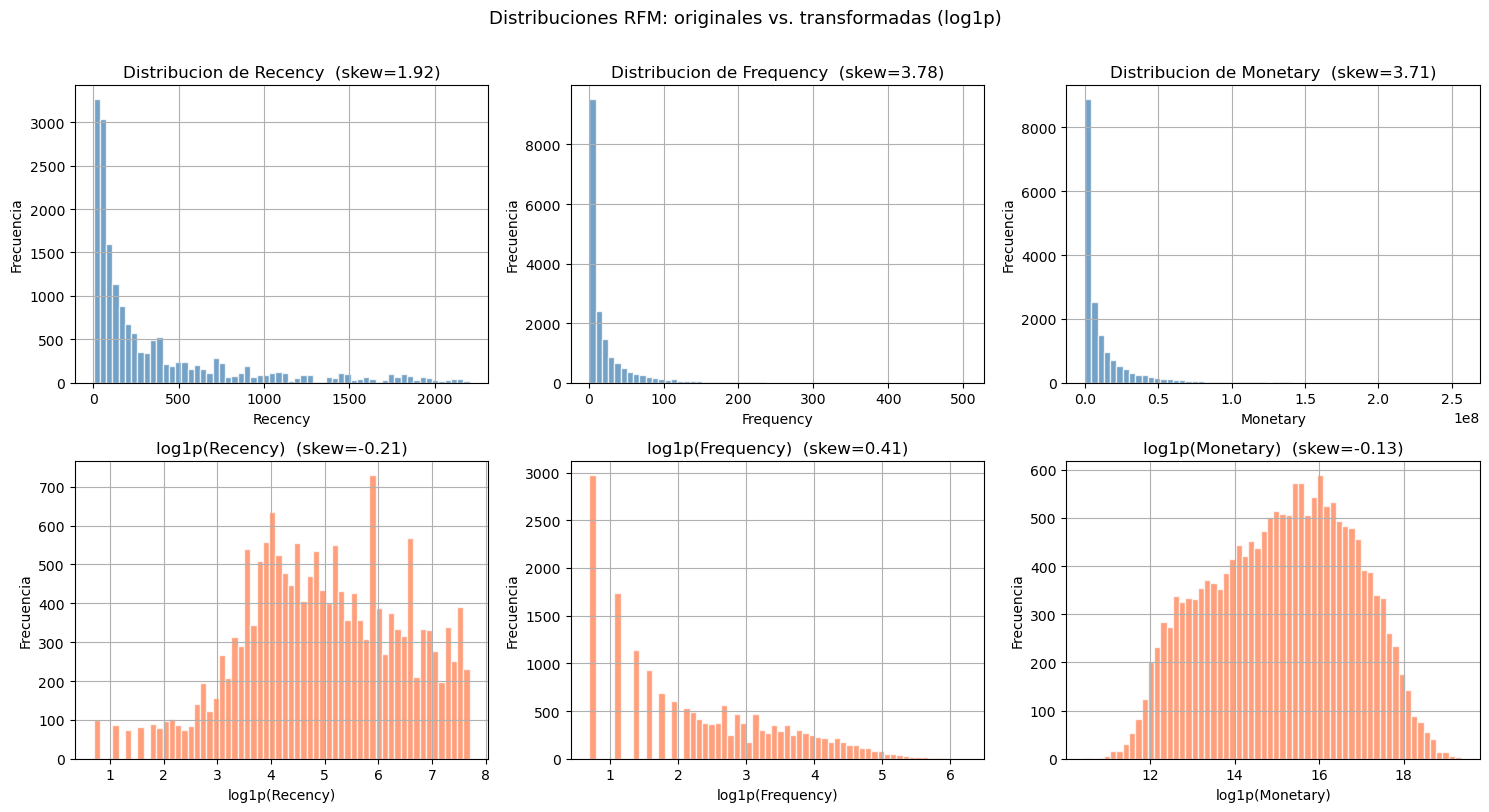

Skewness original vs. log1p:
  Recency   : original=  1.92  |  log1p=-0.21
  Frequency : original=  3.78  |  log1p= 0.41
  Monetary  : original=  3.71  |  log1p=-0.13

Estadisticas tras log1p + StandardScaler:


,Recency_scaled,Frequency_scaled,Monetary_scaled
count,17459.000,17459.000,17459.000
mean,0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-2.865,-1.287,-2.777
25%,-0.701,-0.961,-0.766
50%,-0.023,-0.079,0.066
75%,0.764,0.773,0.776
max,1.845,3.153,2.525


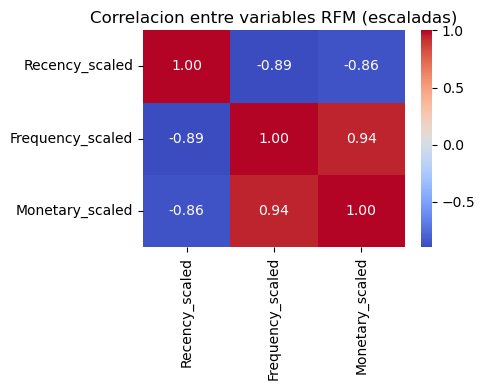

In [10]:
# ── Distribuciones originales vs. log-transformadas ──────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    axes[0, i].hist(rfm[col], bins=60, color='steelblue', alpha=0.75, edgecolor='white')
    axes[0, i].set_title(f'Distribucion de {col}  (skew={rfm[col].skew():.2f})')
    axes[0, i].set_xlabel(col); axes[0, i].set_ylabel('Frecuencia')
    axes[0, i].grid(True)

    axes[1, i].hist(np.log1p(rfm[col]), bins=60, color='coral', alpha=0.75, edgecolor='white')
    log_skew = np.log1p(rfm[col]).skew()
    axes[1, i].set_title(f'log1p({col})  (skew={log_skew:.2f})')
    axes[1, i].set_xlabel(f'log1p({col})'); axes[1, i].set_ylabel('Frecuencia')
    axes[1, i].grid(True)

plt.suptitle('Distribuciones RFM: originales vs. transformadas (log1p)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# ── Skewness ──────────────────────────────────────────────────────────────────
print('Skewness original vs. log1p:')
for col in ['Recency', 'Frequency', 'Monetary']:
    print(f'  {col:10s}: original={rfm[col].skew():6.2f}  |  log1p={np.log1p(rfm[col]).skew():5.2f}')

# ── Transformacion logaritmica + StandardScaler (estilo profesor) ─────────────
rfm_log = rfm[['customer_id']].copy()
for col in ['Recency', 'Frequency', 'Monetary']:
    rfm_log[f'{col}_log'] = np.log1p(rfm[col])

log_cols = ['Recency_log', 'Frequency_log', 'Monetary_log']
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log[log_cols]),
    columns=['Recency_scaled', 'Frequency_scaled', 'Monetary_scaled']
)

print('\nEstadisticas tras log1p + StandardScaler:')
display(rfm_scaled.describe().round(3))

# ── Matriz de correlacion ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(rfm_scaled.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlacion entre variables RFM (escaladas)')
plt.tight_layout()
plt.show()

## 3. Clustering con K-Means

#### PREGUNTA 3:
* Realiza una clusterización con K-Means sobre los datos de RFM calculados previamente

#### RESPUESTA:

Desde una perspectiva de negocio, la segmentación RFM clásica suele identificar entre **3 y 6 grupos** significativos (p. ej., Champions, Leales, En riesgo, Hibernando, Perdidos). Buscar K=2 tendría poco valor accionable, y más de 8 haría los segmentos difíciles de gestionar. Por ello exploramos el rango **K ∈ [3, 7]**.

Se usa la función `find_optimal_k()` proporcionada, que evalúa el **Silhouette Score** (calidad de separación entre clusters) y el **método del codo** (SSE). El K con mayor silhouette score dentro de un rango razonable de negocio es el seleccionado.

Training model for K=3
Training model for K=4
Training model for K=5
Training model for K=6
Training model for K=7


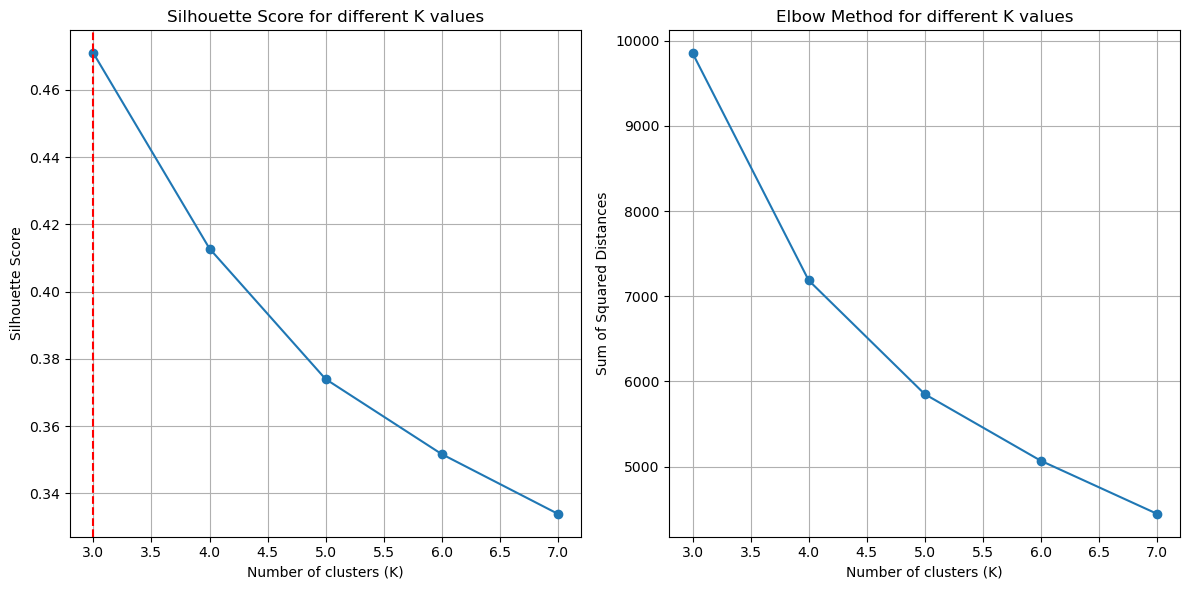

Optimal number of clusters: 3
Perfil de clusters:


,N_clientes,R_media,F_media,M_media,M_mediana,% clientes
Cluster,,,,,,
0,6448,148.9,9.8,5383185.3,4626639.0,36.9
1,5075,33.1,58.8,32550564.7,24064950.0,29.1
2,5936,855.6,1.8,828240.3,575358.0,34.0


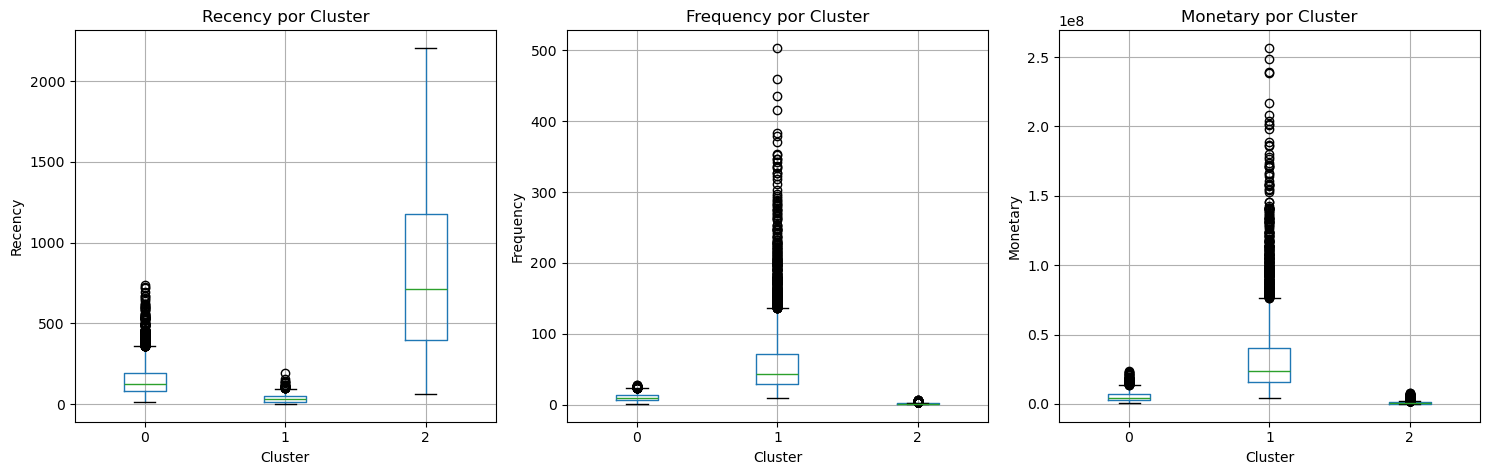

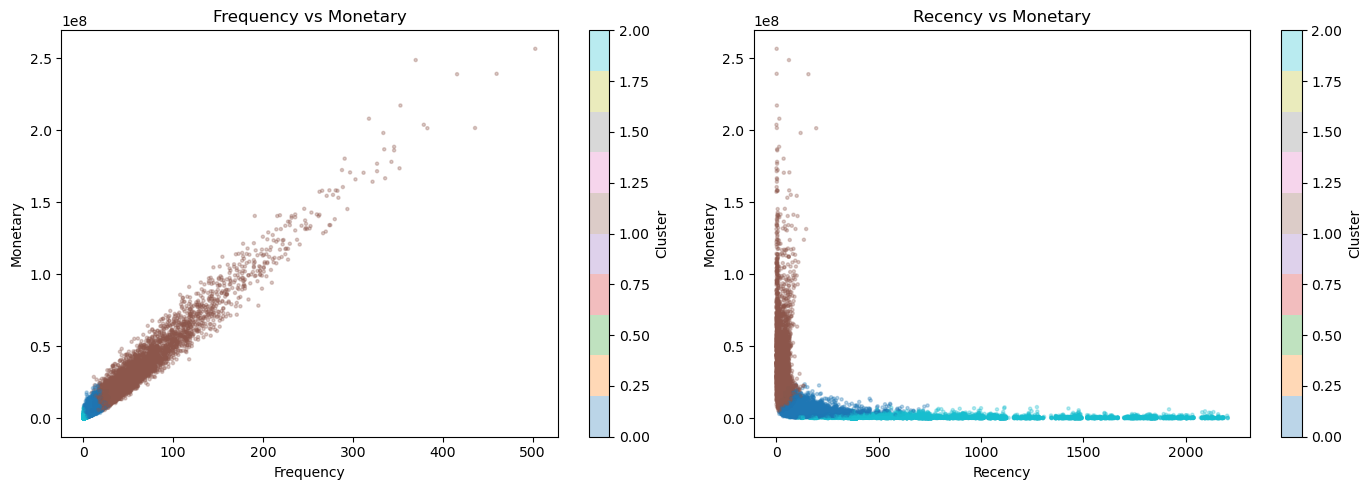

In [11]:
# ── Buscar K óptimo (rango de negocio: 3-7) ──────────────────────────────────
optimal_k = find_optimal_k(rfm_scaled.values, min_k=3, max_k=7)

# ── Entrenar K-Means con el K óptimo ─────────────────────────────────────────
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10,
                algorithm='lloyd', random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled.values)

# ── Perfil de cada cluster ────────────────────────────────────────────────────
cluster_profile = rfm.groupby('Cluster').agg(
    N_clientes = ('customer_id', 'count'),
    R_media    = ('Recency',   'mean'),
    F_media    = ('Frequency', 'mean'),
    M_media    = ('Monetary',  'mean'),
    M_mediana  = ('Monetary',  'median')
).round(1)
cluster_profile['% clientes'] = (cluster_profile['N_clientes'] / len(rfm) * 100).round(1)
print('Perfil de clusters:')
display(cluster_profile)

# ── Boxplots por cluster ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    rfm.boxplot(column=col, by='Cluster', ax=ax)
    ax.set_title(f'{col} por Cluster')
    ax.set_xlabel('Cluster'); ax.set_ylabel(col)
plt.suptitle('')
plt.tight_layout()
plt.show()

# ── Scatter plot F vs M coloreado por cluster ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_kw = dict(alpha=0.3, s=5, cmap='tab10')

sc = axes[0].scatter(rfm['Frequency'], rfm['Monetary'],
                     c=rfm['Cluster'], **scatter_kw)
axes[0].set_xlabel('Frequency'); axes[0].set_ylabel('Monetary')
axes[0].set_title('Frequency vs Monetary')
plt.colorbar(sc, ax=axes[0], label='Cluster')

sc2 = axes[1].scatter(rfm['Recency'], rfm['Monetary'],
                      c=rfm['Cluster'], **scatter_kw)
axes[1].set_xlabel('Recency'); axes[1].set_ylabel('Monetary')
axes[1].set_title('Recency vs Monetary')
plt.colorbar(sc2, ax=axes[1], label='Cluster')

plt.tight_layout()
plt.show()

#### PREGUNTA 4:
* ¿Qué interpretación haces de los resultados obtenidos con la clusterización? ¿Qué acciones propondrías hacer sobre ellos?

#### RESPUESTA:

El algoritmo seleccionó **K=3** como número óptimo de clusters según el Silhouette Score. Los tres segmentos obtenidos son:

| Cluster | N clientes | % | Recency (días) | Frequency | Monetary (IDR) | Perfil |
|---------|-----------|---|---------------|-----------|----------------|--------|
| **0** | 6.448 | 36.9% | 149 | 9.8 | 5.383.185 | Clientes regulares moderados |
| **1** | 5.075 | 29.1% | **33** | **58.8** | **32.550.565** | Champions / VIP |
| **2** | 5.936 | 34.0% | **856** | 1.8 | 828.240 | Clientes perdidos / inactivos |

**Interpretación:**

- **Cluster 1 – Champions (29.1%)**: Son los clientes más valiosos. Compraron hace muy poco (R=33 días), lo hacen con mucha frecuencia (F=58.8 transacciones) y gastan una media de 32.5 millones IDR. Representan casi un tercio de la base activa y son el motor del negocio.
- **Cluster 0 – Regulares (36.9%)**: Clientes con comportamiento intermedio. Compran con cierta regularidad (F≈10) y un gasto moderado. Son candidatos a subir al segmento Champions con la estrategia adecuada.
- **Cluster 2 – Perdidos (34.0%)**: No compran desde hace más de 2 años de media (R=856 días), casi nunca repiten (F=1.8) y gastan muy poco. Son clientes que han abandonado la plataforma.

**Acciones recomendadas:**

| Cluster | Acción |
|---------|--------|
| Champions (1) | Programa VIP, acceso anticipado a colecciones, descuentos exclusivos por fidelidad. |
| Regulares (0) | Campaña de upselling/cross-selling, incentivo en la siguiente compra, newsletter personalizada. |
| Perdidos (2) | Win-back agresivo con descuento fuerte; si no reaccionan, reducir inversión en comunicación para este grupo. |

**Insight clave**: El 34% de los clientes lleva sin comprar más de 2 años. La **retención y reactivación** son prioritarias frente a la captación de nuevos clientes.

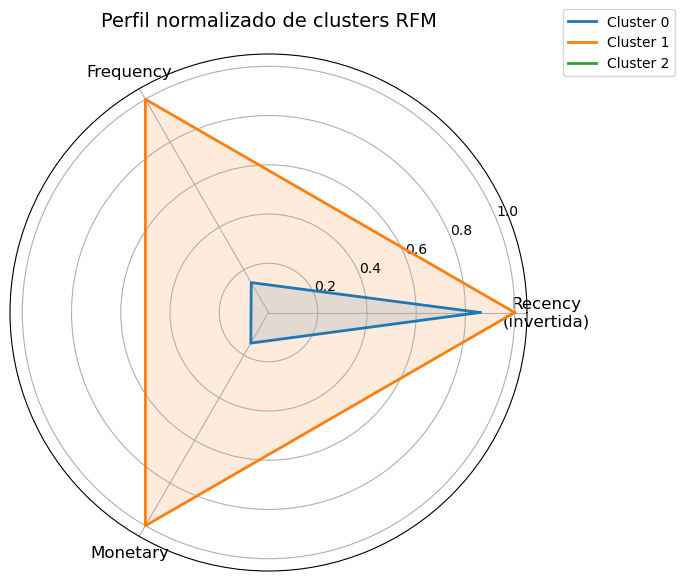

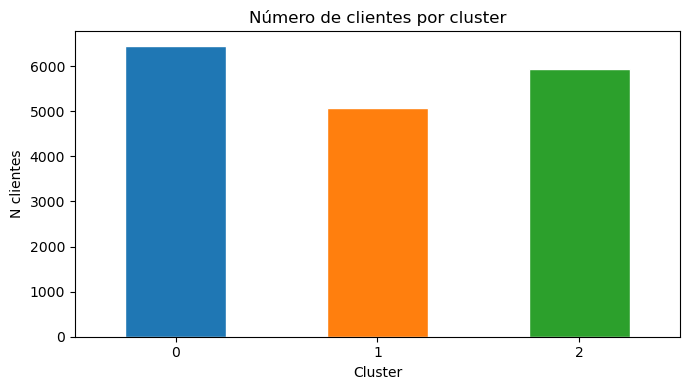

In [12]:
# ── Radar chart (spider plot) del perfil medio de cada cluster ───────────────
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

# Normalizar medias de R, F, M al rango [0,1] para el radar
profile_norm = cluster_profile[['R_media', 'F_media', 'M_media']].copy()
for col in profile_norm.columns:
    profile_norm[col] = (profile_norm[col] - profile_norm[col].min()) / \
                        (profile_norm[col].max() - profile_norm[col].min() + 1e-9)

# Para Recency, un valor más bajo es mejor → invertimos
profile_norm['R_media'] = 1 - profile_norm['R_media']
profile_norm.columns = ['Recency\n(invertida)', 'Frequency', 'Monetary']

categories = profile_norm.columns.tolist()
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
colors = plt.cm.tab10.colors

for i, (cluster_id, row) in enumerate(profile_norm.iterrows()):
    values = row.tolist() + row.tolist()[:1]
    ax.plot(angles, values, color=colors[i], linewidth=2, label=f'Cluster {cluster_id}')
    ax.fill(angles, values, color=colors[i], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, size=12)
ax.set_title('Perfil normalizado de clusters RFM', size=14, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

# ── Distribución de clientes por cluster ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
cluster_profile['N_clientes'].plot(kind='bar', ax=ax, color=list(colors[:optimal_k]), edgecolor='white')
ax.set_title('Número de clientes por cluster')
ax.set_xlabel('Cluster'); ax.set_ylabel('N clientes')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 4. Consideración de variables adicionales sobre los clientes

In [13]:
# Procesamiento de variables asociadas a los clientes
max_join_date = str(customers['first_join_date'].max())
print(max_join_date)
customers['first_join_date'] = pd.to_datetime(customers['first_join_date'])
customers['age'] = int(max_join_date[:4]) - pd.to_datetime(customers['birthdate']).dt.year

# Tiempo que un cliente ha permanecido activo con la empresa desde la fecha en que se unió por primera vez.
customers['tenure_days'] = (pd.to_datetime(max_join_date) - customers['first_join_date']).dt.days
display(customers.head(2))

2022-07-31


,customer_id,first_name,last_name,username,email,gender,birthdate,device_type,device_id,device_version,home_location_lat,home_location_long,home_location,home_country,first_join_date,age,tenure_days
0,2870,Lala,Maryati,671a0865-ac4e-4dc4-9c4f-c286a1176f7e,671a0865_ac4e_4dc4_9c4f_c286a1176f7e@startupca...,F,1996-06-14,iOS,c9c0de76-0a6c-4ac2-843f-65264ab9fe63,iPhone; CPU iPhone OS 14_2_1 like Mac OS X,-1.043345,101.360523,Sumatera Barat,Indonesia,2019-07-21,26,1106
1,8193,Maimunah,Laksmiwati,83be2ba7-8133-48a4-bbcb-b46a2762473f,83be2ba7_8133_48a4_bbcb_b46a2762473f@zakyfound...,F,1993-08-16,Android,fb331c3d-f42e-40fe-afe2-b4b73a8a6e25,Android 2.2.1,-6.212489,106.818850,Jakarta Raya,Indonesia,2017-07-16,29,1841


#### PREGUNTA 5:
* Realiza un análisis exploratorio de las demás variables de clientes, y relaciónalas con la tabla de transacciones.
* ¿Es necesario realizar algún tipo de transformación sobre estas nuevas variables para hacer clustering con ellas?

#### RESPUESTA:

Tras cruzar la tabla de clientes con los datos RFM (17.459 clientes activos), se analizan las variables disponibles:

- **`gender`**: 64.4% mujeres (F) y 35.6% hombres (M). El gasto medio es muy similar: F=11.5M IDR, M=12.1M IDR. El género no diferencia significativamente el comportamiento de compra en términos monetarios.
- **`device_type`**: 76.9% Android, 23.1% iOS. El gasto medio también es similar: Android=11.8M IDR, iOS=11.4M IDR. No se observa una ventaja clara del usuario iOS en términos de gasto.
- **`age`**: Distribución aproximadamente normal (skew≈0.5), centrada alrededor de los 26-30 años. No requiere transformación logarítmica.
- **`tenure_days`**: Días desde el registro. Distribución más irregular; se aplica `log1p` por precaución para homogeneizar la escala junto al resto de variables numéricas.

**Transformaciones necesarias**: `StandardScaler` sobre todas las variables numéricas (incluyendo las RFM ya transformadas con `log1p`) para que todas tengan la misma escala en el algoritmo. Las variables categóricas (`gender`, `device_type`) se pasan directamente a K-Prototypes sin codificar.

Clientes con RFM + variables demograficas: 17,459


,customer_id,gender,device_type,age,tenure_days,Recency,Frequency,Monetary,Cluster
0,73093,F,Android,30,372,186,2,547180.0,2
1,97883,F,Android,23,1827,180,10,12678519.0,0
2,28855,F,Android,30,1960,1961,1,564985.0,2


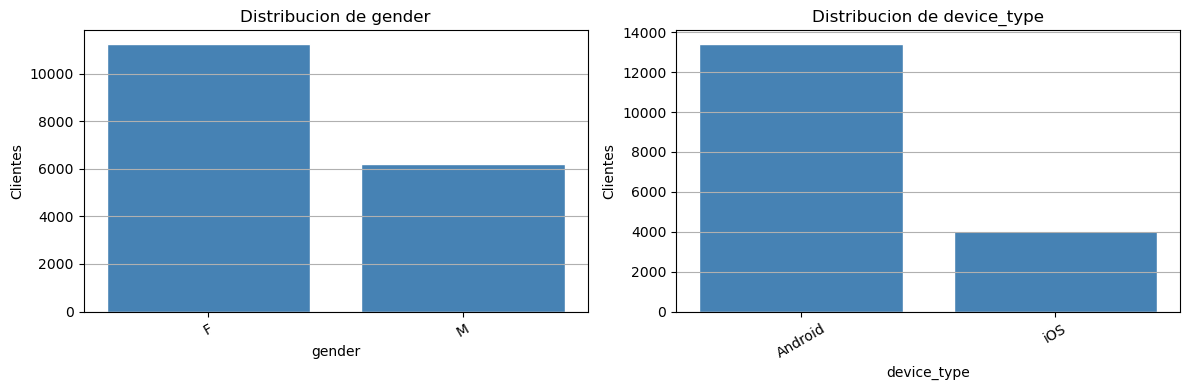

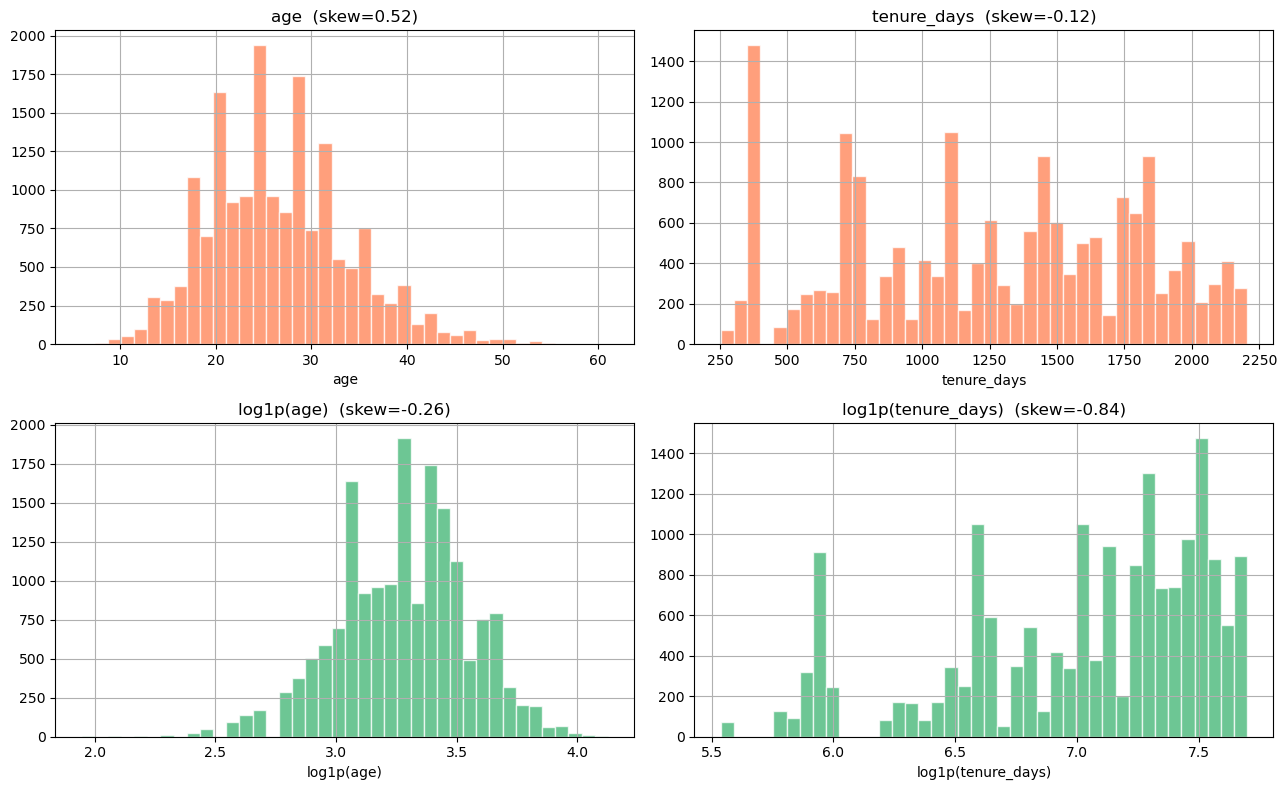


Gasto medio (Monetary) por genero:


,mean,median,count
gender,,,
F,11508402.0,4057455.0,11253
M,12136205.0,4203005.0,6206



Gasto medio (Monetary) por tipo de dispositivo:


,mean,median,count
device_type,,,
Android,11836092.0,4174002.0,13429
iOS,11383237.0,3916344.0,4030


In [14]:
# ── Merge variables de clientes con RFM ──────────────────────────────────────
customer_rfm = customers[['customer_id', 'gender', 'device_type', 'age', 'tenure_days']].merge(
    rfm, on='customer_id', how='inner'
)
print(f'Clientes con RFM + variables demograficas: {len(customer_rfm):,}')
display(customer_rfm.head(3))

# ── Distribuciones de variables categoricas ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['gender', 'device_type']):
    vc = customer_rfm[col].value_counts()
    ax.bar(vc.index, vc.values, color='steelblue', edgecolor='white')
    ax.set_title(f'Distribucion de {col}')
    ax.set_xlabel(col); ax.set_ylabel('Clientes')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(True, axis='y')
plt.tight_layout(); plt.show()

# ── Distribuciones de variables numericas ─────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, col in enumerate(['age', 'tenure_days']):
    skew_val = customer_rfm[col].skew()
    axes[0, i].hist(customer_rfm[col].dropna(), bins=40, color='coral', alpha=0.75, edgecolor='white')
    axes[0, i].set_title(f'{col}  (skew={skew_val:.2f})')
    axes[0, i].set_xlabel(col)
    axes[0, i].grid(True)

    log_col = np.log1p(customer_rfm[col].dropna())
    axes[1, i].hist(log_col, bins=40, color='mediumseagreen', alpha=0.75, edgecolor='white')
    axes[1, i].set_title(f'log1p({col})  (skew={log_col.skew():.2f})')
    axes[1, i].set_xlabel(f'log1p({col})')
    axes[1, i].grid(True)
plt.tight_layout(); plt.show()

# ── Relacion variables demograficas vs RFM ────────────────────────────────────
print('\nGasto medio (Monetary) por genero:')
display(customer_rfm.groupby('gender')['Monetary'].agg(['mean','median','count']).round(0))

print('\nGasto medio (Monetary) por tipo de dispositivo:')
display(customer_rfm.groupby('device_type')['Monetary'].agg(['mean','median','count']).round(0))

#### PREGUNTA 6:
* Justifica qué nuevas variables consideras relevante para la segmentación y, en base a ellas, aplica las técnicas adecuadas de clustering para poder segmentar los datos.

#### RESPUESTA:

Se seleccionan las siguientes variables adicionales para enriquecer la segmentacion:

| Variable | Tipo | Justificacion |
|----------|------|---------------|
| `gender` | Categorica nominal | Permite detectar segmentos diferenciados por genero, util para personalizar producto y comunicacion. |
| `device_type` | Categorica nominal | Refleja el canal de uso (iOS vs Android) con posibles diferencias en comportamiento y poder adquisitivo. |
| `age` | Numerica continua | La edad condiciona las preferencias de producto y el ciclo de vida del cliente. |
| `tenure_days` | Numerica continua (sesgada) | Indica la antiguedad del cliente: los mas antiguos suelen ser mas valiosos y fieles. |

**Por que K-Prototypes y no K-Means:**  
K-Means solo funciona con variables numericas (distancia euclidea). Aplicarlo sobre variables categoricas codificadas numericamente (e.g., gender → 0/1) es incorrecto porque asume una relacion ordinal que no existe. **K-Prototypes** combina distancia euclidea para numericas con distancia de Hamming para categoricas, siendo el algoritmo adecuado para datos mixtos.

**Transformaciones aplicadas:**
- `tenure_days` → `log1p(tenure_days)` por sesgo positivo.
- Variables RFM → ya transformadas con `log1p`.
- Variables numericas estandarizadas con `StandardScaler` (media=0, varianza=1).

Shape datos: (17459, 7), indices categoricos: [5, 6]
Training model for K=3
Training model for K=4
Training model for K=5
Training model for K=6
Training model for K=7


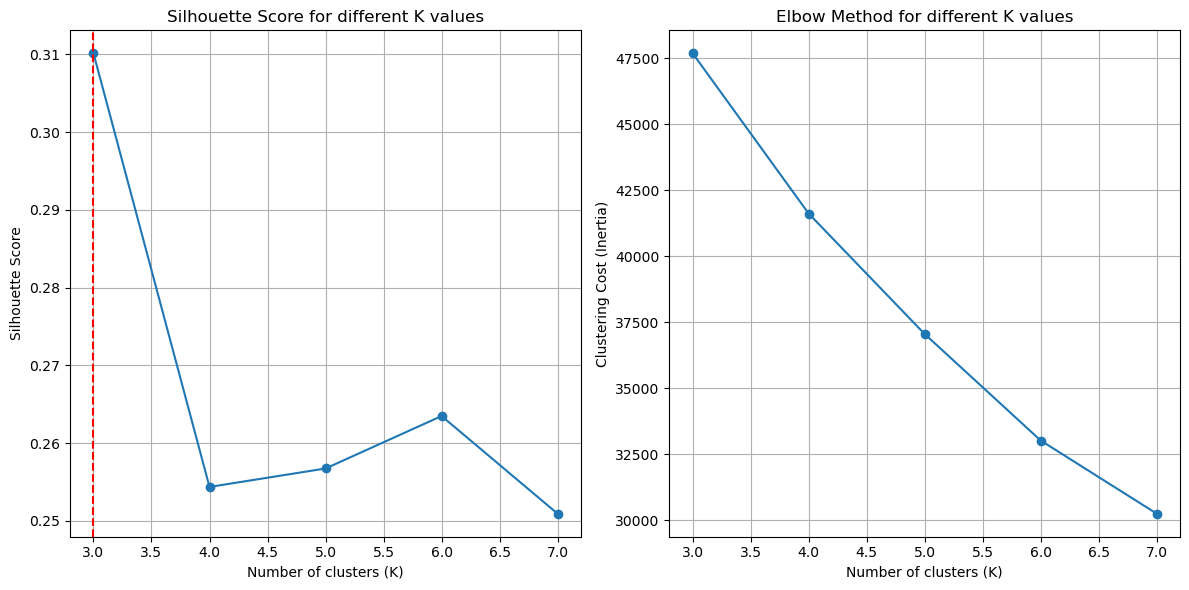

Optimal number of clusters: 3
Perfil de clusters K-Prototypes:


,N,R_media,F_media,M_media,edad_media,tenure_med,pct_F,pct_iOS,% clientes
Cluster_kp,,,,,,,,,
0,3715,139.82,8.03,4437422.45,26.73,512.0,0.66,0.24,21.3
1,6863,770.33,3.04,1528989.15,26.50,1463.0,0.64,0.23,39.3
2,6881,58.30,46.71,25845495.18,26.41,1477.0,0.63,0.23,39.4


In [15]:
# ── Preparacion del dataset para K-Prototypes ────────────────────────────────
kp_df = customer_rfm[['customer_id','Recency','Frequency','Monetary',
                        'age','tenure_days','gender','device_type']].dropna().copy()

# Transformaciones logaritmicas en variables sesgadas
for col in ['Recency', 'Frequency', 'Monetary', 'tenure_days']:
    kp_df[f'{col}_log'] = np.log1p(kp_df[col])

num_cols = ['Recency_log', 'Frequency_log', 'Monetary_log', 'age', 'tenure_days_log']
cat_cols  = ['gender', 'device_type']

# StandardScaler (igual que en los apuntes del profesor)
scaler2 = StandardScaler()
kp_df[num_cols] = scaler2.fit_transform(kp_df[num_cols])

# Array para K-Prototypes: numericas primero, categoricas al final
X_kp = kp_df[num_cols + cat_cols].values
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
print(f'Shape datos: {X_kp.shape}, indices categoricos: {cat_idx}')

# ── Buscar K optimo ───────────────────────────────────────────────────────────
optimal_k_kp = find_optimal_k_kprototypes(X_kp, cat_idx=cat_idx, min_k=3, max_k=7, n_jobs=1)

# ── Entrenar K-Prototypes con K optimo ────────────────────────────────────────
kproto = KPrototypes(n_clusters=optimal_k_kp, init='Huang', n_init=2, random_state=42)
kp_df['Cluster_kp'] = kproto.fit_predict(X_kp, categorical=cat_idx)

# ── Perfil de clusters ────────────────────────────────────────────────────────
kp_orig = customer_rfm[['customer_id','Recency','Frequency','Monetary',
                          'age','tenure_days','gender','device_type']].dropna().copy()
kp_orig['Cluster_kp'] = kp_df['Cluster_kp'].values

profile_kp = kp_orig.groupby('Cluster_kp').agg(
    N          = ('customer_id',  'count'),
    R_media    = ('Recency',      'mean'),
    F_media    = ('Frequency',    'mean'),
    M_media    = ('Monetary',     'mean'),
    edad_media = ('age',          'mean'),
    tenure_med = ('tenure_days',  'median'),
    pct_F      = ('gender',       lambda x: (x == 'F').mean()),
    pct_iOS    = ('device_type',  lambda x: (x == 'iOS').mean())
).round(2)
profile_kp['% clientes'] = (profile_kp['N'] / len(kp_orig) * 100).round(1)
print('Perfil de clusters K-Prototypes:')
display(profile_kp)

#### PREGUNTA 7:
* ¿Qué insights adicionales se derivan del uso de estas variables extra? ¿Qué acciones concretas recomendarías sobre los clientes?

#### RESPUESTA:

K-Prototypes también seleccionó **K=3**. Los clusters enriquecidos con variables demográficas son:

| Cluster | N | % | Recency | Frequency | Monetary (IDR) | Edad | Tenure (días) | % Mujeres | % iOS |
|---------|---|---|---------|-----------|----------------|------|--------------|-----------|-------|
| **0** | 3.715 | 21.3% | 140 | 8.0 | 4.437.422 | 26.7 | 512 | 66% | 24% |
| **1** | 6.863 | 39.3% | 770 | 3.0 | 1.528.989 | 26.5 | 1.463 | 64% | 23% |
| **2** | 6.881 | 39.4% | 58 | 46.7 | 25.845.495 | 26.4 | 1.477 | 63% | 23% |

**Insights adicionales:**

- **Cluster 2 – Champions activos con alta antigüedad**: Son los clientes más valiosos (M=25.8M IDR, F=46.7). Llevan mucho tiempo en la plataforma (tenure≈1.477 días ≈ 4 años) y siguen comprando activamente (R=58 días). Son usuarios fieles y consolidados.
- **Cluster 1 – Abandonados con larga trayectoria**: Clientes que llevan mucho tiempo registrados (tenure≈1.463 días) pero llevan casi 2 años y medio sin comprar (R=770 días). Conocen la plataforma pero han dejado de usarla.
- **Cluster 0 – Clientes recientes moderados**: Antigüedad baja (tenure≈512 días ≈ 1.4 años), compran con cierta regularidad. Son los clientes más nuevos del conjunto activo.

**Sobre género y dispositivo**: La proporción de mujeres (~64%) y de usuarios iOS (~23%) es prácticamente idéntica en los tres clusters, lo que indica que estas variables **no discriminan** entre segmentos de valor. Sin embargo, su inclusión en K-Prototypes añade riqueza al perfil para personalizar comunicaciones.

**Acciones concretas:**

| Cluster | Acción |
|---------|--------|
| Champions (2) | Programa de fidelización VIP. Dada su antigüedad, ofrecerles beneficios exclusivos para mantener su lealtad a largo plazo. |
| Abandonados (1) | Campaña de reactivación con referencia a su historial de compras y oferta especial por su antigüedad como clientes. |
| Recientes (0) | Programa de onboarding: incentivo en 2ª y 3ª compra para acelerar la conversión hacia el segmento Champions. |

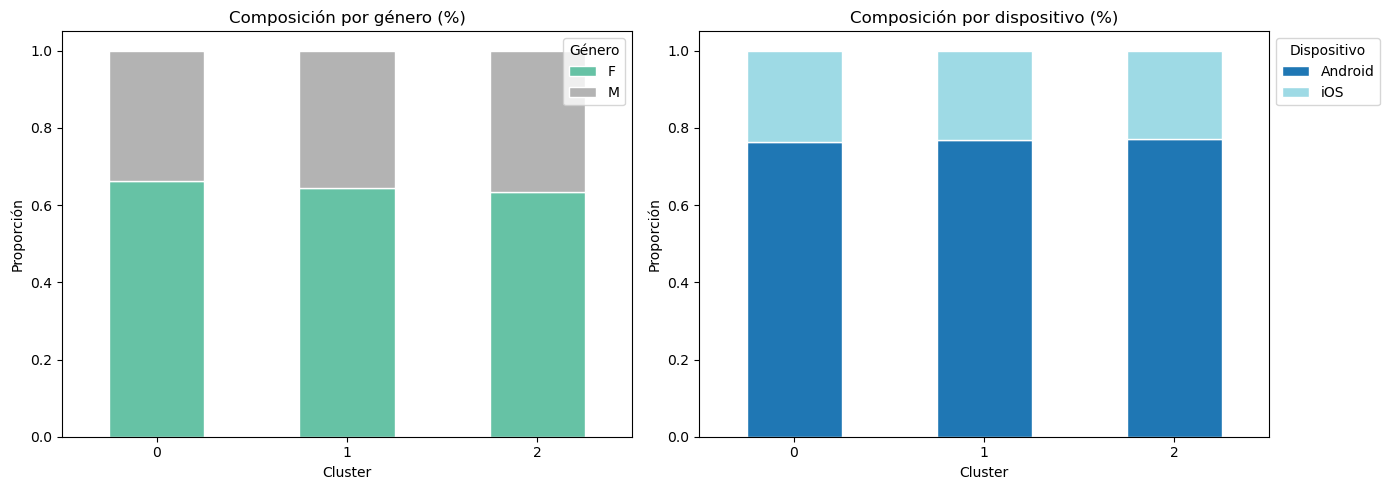

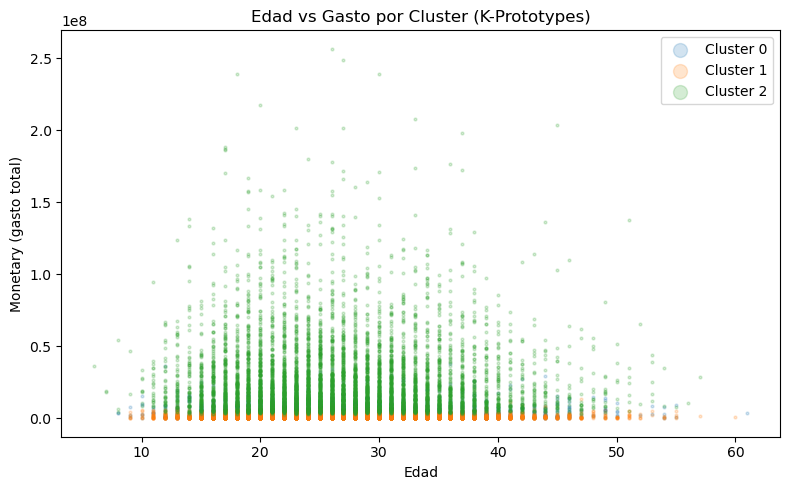

In [16]:
# ── Barras apiladas: composición de género y dispositivo por cluster ──────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gender_comp = kp_orig.groupby(['Cluster_kp', 'gender']).size().unstack(fill_value=0)
gender_comp.div(gender_comp.sum(axis=1), axis=0).plot(
    kind='bar', stacked=True, ax=axes[0], colormap='Set2', edgecolor='white'
)
axes[0].set_title('Composición por género (%)'); axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Proporción'); axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Género')

device_comp = kp_orig.groupby(['Cluster_kp', 'device_type']).size().unstack(fill_value=0)
device_comp.div(device_comp.sum(axis=1), axis=0).plot(
    kind='bar', stacked=True, ax=axes[1], colormap='tab20', edgecolor='white'
)
axes[1].set_title('Composición por dispositivo (%)'); axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Proporción'); axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Dispositivo', bbox_to_anchor=(1, 1))

plt.tight_layout(); plt.show()

# ── Scatter edad vs monetary por cluster ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))
colors_kp = plt.cm.tab10.colors
for cid in sorted(kp_orig['Cluster_kp'].unique()):
    mask = kp_orig['Cluster_kp'] == cid
    ax.scatter(kp_orig.loc[mask, 'age'], kp_orig.loc[mask, 'Monetary'],
               alpha=0.2, s=4, label=f'Cluster {cid}', color=colors_kp[cid])
ax.set_xlabel('Edad'); ax.set_ylabel('Monetary (gasto total)')
ax.set_title('Edad vs Gasto por Cluster (K-Prototypes)')
ax.legend(markerscale=5); plt.tight_layout(); plt.show()

## 5. Clustering Geográfico con DBSCAN

#### PREGUNTA 8:
* Analiza los datos de geolocalización de los lugares de residencia y realiza una segmentación de clientes en base a dicha información utilizando DBSCAN

#### RESPUESTA:

Se utilizan las variables `home_location_lat` y `home_location_long` de la tabla de clientes para segmentar geográficamente.

**Por qué DBSCAN para clustering geográfico:**
- DBSCAN detecta clusters de **forma arbitraria** (ciudades, regiones), no asume clusters esféricos como K-Means.
- Identifica automáticamente **puntos de ruido** (clientes en zonas muy dispersas o aisladas).
- No requiere especificar el número de clusters a priori.

**Configuración:**
- Se usa la **métrica Haversine** (distancia real sobre la esfera terrestre) convirtiendo coordenadas a radianes.
- **Hiperparámetros clave**: `eps` (radio de vecindad en km) y `min_samples` (mínimo de puntos para formar un cluster). Se prueban distintos valores de `eps` (50 km, 100 km, 200 km) para encontrar una granularidad útil.

Clientes con coordenadas: 100,000


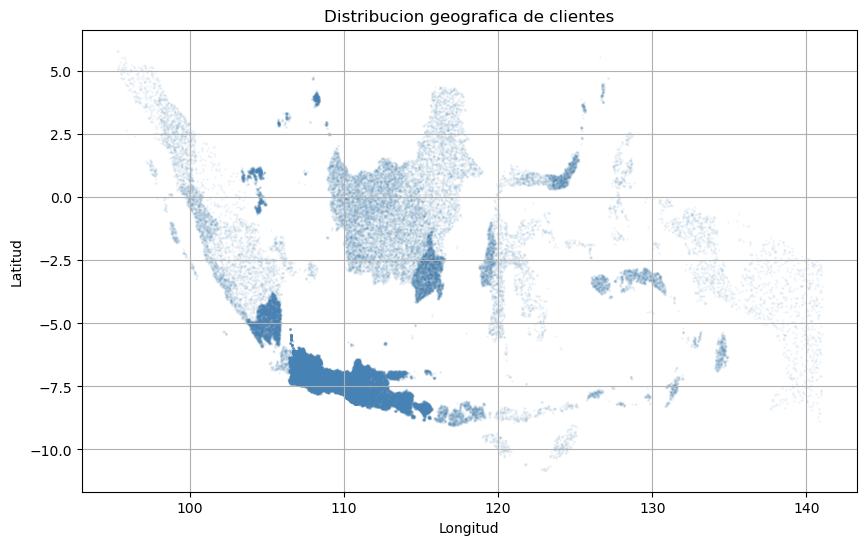

Explorando hiperparametros sobre muestra de 20,000 puntos...
  eps (km)  min_samples   n_clusters    % ruido
        50           30           18       7.8%
       100           50            8       4.0%
       200           50            3       0.6%

Entrenando modelo final sobre todos los datos...
Clusters: 12 | Ruido: 173 (0.2%)


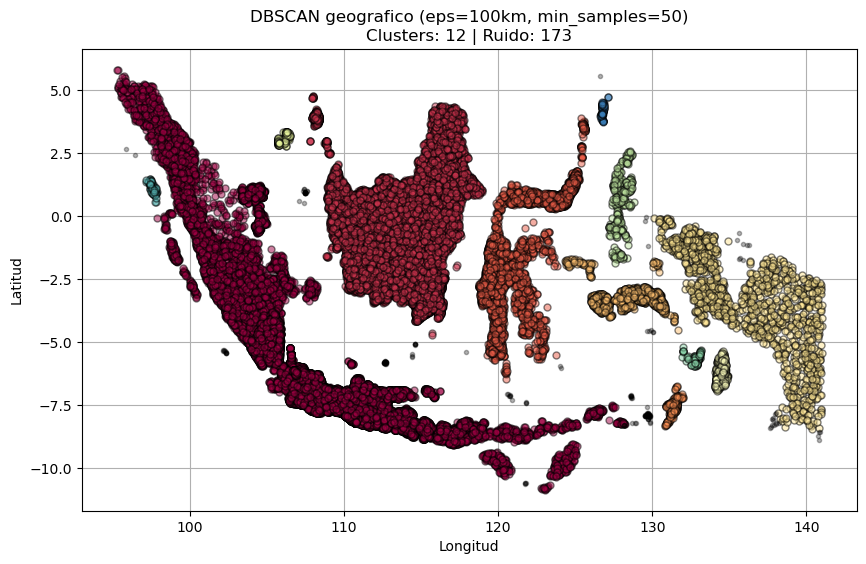


Top 10 clusters geograficos:


,N_clientes,top_region,lat_centroid,lon_centroid
Cluster_geo,,,,
0,74342,Jakarta Raya,-6.411400,108.615352
1,17116,Kalimantan Barat,-0.836288,113.495803
2,4075,Sulawesi Utara,-1.287972,121.604920
4,1545,Maluku,-3.220909,128.399759
5,1372,Papua,-3.327334,136.022204
6,424,Maluku,-6.185119,134.457828
8,306,Maluku Utara,0.593093,127.962653
3,253,Maluku,-7.577118,131.354165
7,164,Kepulauan Riau,3.075100,106.035159


In [17]:
# ── Funcion de visualizacion DBSCAN (estilo apuntes profesor) ────────────────
def plot_dbscan(coords_2d, labels, title):
    """Visualiza clusters DBSCAN distinguiendo core points y border points."""
    core_samples_mask = np.zeros(len(labels), dtype=bool)
    # Aproximamos core points como los que tienen etiqueta != -1 (valido para visualizacion)
    core_samples_mask[labels != -1] = True

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    plt.figure(figsize=(10, 6))
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # negro para ruido
        class_mask = (labels == k)
        xy = coords_2d[class_mask & core_samples_mask]
        plt.plot(xy[:, 1], xy[:, 0], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='k', markersize=5, alpha=0.5)
        xy_border = coords_2d[class_mask & ~core_samples_mask]
        plt.plot(xy_border[:, 1], xy_border[:, 0], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='k', markersize=3, alpha=0.3)
    plt.title(f'{title}\nClusters: {n_clusters} | Ruido: {(labels==-1).sum():,}')
    plt.xlabel('Longitud'); plt.ylabel('Latitud')
    plt.grid(True)
    plt.show()

# ── Datos geoespaciales ───────────────────────────────────────────────────────
geo = customers[['customer_id','home_location_lat','home_location_long',
                  'home_location','home_country']].dropna(
                  subset=['home_location_lat','home_location_long']).copy()
print(f'Clientes con coordenadas: {len(geo):,}')

# ── EDA: scatter geografico ───────────────────────────────────────────────────
plt.figure(figsize=(10, 6))
plt.scatter(geo['home_location_long'], geo['home_location_lat'],
            alpha=0.05, s=1, color='steelblue')
plt.xlabel('Longitud'); plt.ylabel('Latitud')
plt.title('Distribucion geografica de clientes')
plt.grid(True)
plt.show()

# ── Mapa interactivo ─────────────────────────────────────────────────────────
fig_map = px.scatter_geo(
    geo.sample(5000, random_state=42),
    lat='home_location_lat', lon='home_location_long',
    hover_data=['home_location'], opacity=0.4,
    title='Muestra de clientes en mapa (5000 puntos)'
)
fig_map.show()

# ── Exploracion de hiperparametros sobre muestra (20K puntos) ─────────────────
SAMPLE_SIZE = 20000
geo_sample = geo.sample(SAMPLE_SIZE, random_state=42)
coords_sample = np.radians(geo_sample[['home_location_lat','home_location_long']].values)
EARTH_RADIUS_KM = 6371.0

print(f'Explorando hiperparametros sobre muestra de {SAMPLE_SIZE:,} puntos...')
print(f'{"eps (km)":>10} {"min_samples":>12} {"n_clusters":>12} {"% ruido":>10}')
for eps_km, min_s in [(50, 30), (100, 50), (200, 50)]:
    eps = eps_km / EARTH_RADIUS_KM
    lbl = DBSCAN(eps=eps, min_samples=min_s,
                 algorithm='ball_tree', metric='haversine').fit_predict(coords_sample)
    n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
    pct_noise = (lbl == -1).sum() / len(lbl) * 100
    print(f'{eps_km:>10} {min_s:>12} {n_cl:>12} {pct_noise:>9.1f}%')

# ── Modelo final sobre todos los datos ───────────────────────────────────────
print('\nEntrenando modelo final sobre todos los datos...')
coords_rad = np.radians(geo[['home_location_lat','home_location_long']].values)
best_eps_km, best_min_s = 100, 50

db_final = DBSCAN(eps=best_eps_km / EARTH_RADIUS_KM, min_samples=best_min_s,
                  algorithm='ball_tree', metric='haversine')
geo['Cluster_geo'] = db_final.fit_predict(coords_rad)

n_cl_final = len(set(geo['Cluster_geo'])) - (1 if -1 in geo['Cluster_geo'].values else 0)
n_noise = (geo['Cluster_geo'] == -1).sum()
print(f'Clusters: {n_cl_final} | Ruido: {n_noise:,} ({n_noise/len(geo)*100:.1f}%)')

# ── Visualizacion estilo profesor ─────────────────────────────────────────────
plot_dbscan(
    geo[['home_location_lat','home_location_long']].values,
    geo['Cluster_geo'].values,
    f'DBSCAN geografico (eps={best_eps_km}km, min_samples={best_min_s})'
)

# ── Mapa interactivo con clusters ─────────────────────────────────────────────
geo_plot = geo.copy()
geo_plot['Cluster_str'] = geo_plot['Cluster_geo'].apply(
    lambda x: 'Ruido' if x == -1 else f'Cluster {x}'
)
px.scatter_geo(
    geo_plot.sample(10000, random_state=42),
    lat='home_location_lat', lon='home_location_long',
    color='Cluster_str', hover_data=['home_location'], opacity=0.5,
    title=f'Clusters DBSCAN (eps={best_eps_km}km, min_samples={best_min_s})'
).show()

# ── Perfil por cluster ────────────────────────────────────────────────────────
cluster_geo_profile = geo[geo['Cluster_geo'] >= 0].groupby('Cluster_geo').agg(
    N_clientes   = ('customer_id', 'count'),
    top_region   = ('home_location', lambda x: x.value_counts().index[0]),
    lat_centroid = ('home_location_lat',  'mean'),
    lon_centroid = ('home_location_long', 'mean')
).sort_values('N_clientes', ascending=False)
print('\nTop 10 clusters geograficos:')
display(cluster_geo_profile.head(10))


#### PREGUNTA 9:
* ¿Qué insights se derivan de esta segmentación y qué acciones concretas propondrías?

#### RESPUESTA:

DBSCAN identificó **12 clusters geográficos** con solo 173 puntos de ruido (0.2%), lo que indica que casi todos los clientes están en zonas con densidad suficiente. Los clusters se corresponden con las grandes islas e islas de Indonesia:

| Cluster | N clientes | Región principal | Zona geográfica |
|---------|-----------|-----------------|----------------|
| 0 | **74.342** (74.2%) | Jakarta Raya | Java / Sumatra oeste |
| 1 | 17.116 (17.1%) | Kalimantan Barat | Borneo |
| 2 | 4.075 (4.1%) | Sulawesi Utara | Sulawesi |
| 4 | 1.545 (1.5%) | Maluku | Islas Molucas |
| 5 | 1.372 (1.4%) | Papua | Papua |
| Resto | ~1.370 | Maluku Utara, Kepulauan Riau... | Islas periféricas |

**Insights y acciones:**

| Insight | Acción concreta |
|---------|----------------|
| **Cluster 0 (Java) concentra el 74% de los clientes** y tiene un gasto medio de 11.8M IDR. Es el mercado principal. | Priorizar logística, inventario y marketing digital en Java. Negociar acuerdos con operadores de última milla en Jakarta y ciudades adyacentes. |
| **Cluster 1 (Borneo/Kalimantan)** es el segundo mercado con 17.116 clientes y gasto medio de 11.6M IDR, similar a Java. | Expandir cobertura logística en Kalimantan; tiene potencial de crecimiento similar al mercado principal. |
| **Clusters pequeños en Maluku y Papua** tienen poco volumen pero gasto medio competitivo (10-12M IDR). | Evaluar rentabilidad del envío a estas islas; considerar puntos de recogida o asociaciones con distribuidores locales. |
| **173 clientes de ruido** (zonas muy aisladas) con coste logístico probablemente elevado. | Revisar si los márgenes justifican el envío o redirigir a puntos de recogida alternativos. |

**Conclusión**: La distribución geográfica es muy desigual — Java concentra tres de cada cuatro clientes. Sin embargo, Kalimantan presenta un potencial de crecimiento significativo con un perfil de gasto equivalente al mercado principal.

Clusters geográficos ordenados por gasto medio (Monetary):


,N,R_media,F_media,M_media,top_region
Cluster_geo,,,,,
10,15,364.7,29.5,16806970.6,Sumatera Utara
11,12,247.7,22.4,12873847.4,Sulawesi Utara
5,259,342.2,22.6,12170464.8,Papua
0,12890,355.2,21.5,11845741.3,Jakarta Raya
7,34,164.8,18.8,11665384.0,Kepulauan Riau
1,3087,353.4,21.2,11578088.8,Kalimantan Barat
4,267,349.8,20.6,11372655.0,Maluku
2,659,383.0,20.2,11013097.8,Sulawesi Utara
9,23,578.7,20.7,10859219.9,Maluku


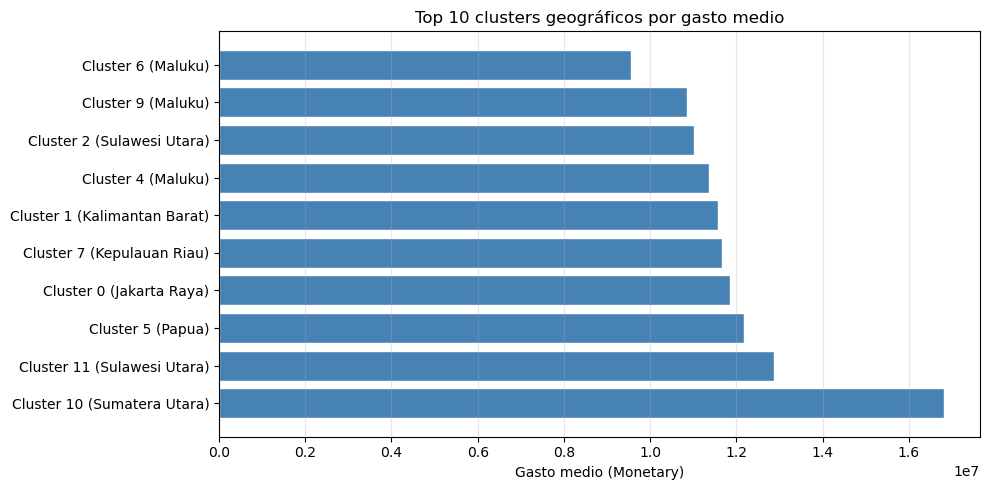

In [18]:
# ── Cruce de clusters geográficos con métricas RFM ────────────────────────────
geo_rfm = geo.merge(rfm, on='customer_id', how='inner')

geo_rfm_profile = geo_rfm[geo_rfm['Cluster_geo'] >= 0].groupby('Cluster_geo').agg(
    N          = ('customer_id', 'count'),
    R_media    = ('Recency',   'mean'),
    F_media    = ('Frequency', 'mean'),
    M_media    = ('Monetary',  'mean'),
    top_region = ('home_location', lambda x: x.value_counts().index[0])
).round(1).sort_values('M_media', ascending=False)

print('Clusters geográficos ordenados por gasto medio (Monetary):')
display(geo_rfm_profile.head(10))

# ── Gráfico: Monetary medio por cluster geográfico ────────────────────────────
top_clusters = geo_rfm_profile.head(10).reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(range(len(top_clusters)), top_clusters['M_media'],
               color='steelblue', edgecolor='white')
ax.set_yticks(range(len(top_clusters)))
ax.set_yticklabels([f'Cluster {r} ({n})' for r, n in
                    zip(top_clusters['Cluster_geo'], top_clusters['top_region'])])
ax.set_xlabel('Gasto medio (Monetary)')
ax.set_title('Top 10 clusters geográficos por gasto medio')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()